# 3.5. Propuesta: modelos híbridos

Random Forest y XGBoost quedaron empatados estadísticamente. La pregunta natural es si **combinarlos**
produce un modelo mejor que cada uno. Se prueban tres mezclas, definidas antes de mirar la prueba:

1. **Híbrido RF + XGBoost** con peso óptimo de Bates y Granger (1969).
2. **RF + SVR**: la pareja fuerte con errores más distintos.
3. **Super Learner** (van der Laan, Polley y Hubbard, 2007): combinación convexa de los 7 modelos.

## Formulación

Para dos modelos con errores $e_R = y - \hat y_R$ y $e_X = y - \hat y_X$:

$$\hat y_H(x) = w\,\hat y_R(x) + (1-w)\,\hat y_X(x), \qquad w \in [0,1]$$

$$\mathrm{MSE}(w) = w^2\sigma_R^2 + (1-w)^2\sigma_X^2 + 2w(1-w)\sigma_{RX}$$

$$w^* = \frac{\sigma_X^2 - \sigma_{RX}}{\sigma_R^2 + \sigma_X^2 - 2\sigma_{RX}}, \qquad
\mathrm{MSE}(w^*) = \frac{\sigma_R^2\sigma_X^2 - \sigma_{RX}^2}{\sigma_R^2 + \sigma_X^2 - 2\sigma_{RX}}$$

La ganancia frente al mejor modelo individual depende de la correlación de errores $\rho$: si $\rho \to 1$,
$\mathrm{MSE}(w^*) \to \min(\sigma_R^2, \sigma_X^2)$ y combinar no aporta.

El Super Learner generaliza a $M$ modelos:

$$\hat y_{SL}(x) = \sum_{m=1}^{M} w_m\,\hat y_m(x), \qquad
\mathbf w = \arg\min_{\mathbf w \ge 0,\ \mathbf 1^\top \mathbf w = 1} \lVert \mathbf y - P\mathbf w \rVert^2$$

donde $P$ contiene predicciones *out-of-fold* de cada modelo. Su desigualdad de oráculo garantiza que,
asintóticamente, rinde tanto como la mejor combinación convexa.

## Protocolo sin fuga

* **CV externa:** en cada pliegue externo $k$ los pesos se estiman con predicciones OOF de un
  GroupKFold(3) interno sobre el entrenamiento externo $k$ (hiperparámetros del pliegue $k$) y se aplican al
  pliegue externo $k$.
* **Prueba:** los pesos se estiman con las predicciones OOF externas de todo el entrenamiento (train) y se aplican a las
  predicciones de los modelos finales. La prueba nunca interviene en la estimación de pesos.

In [1]:
import sys, warnings, json, pickle
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.viz import set_style
import run_blend, run_blend2

C.set_global_seed()
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
OUT = C.RESULTS_DIR / "blend"

## 3.5.1 ¿Se equivocan los modelos en los mismos activos?

Correlación de los errores *out-of-fold* externos (cada fila del entrenamiento (train) predicha una vez, sin haber sido
vista) del mejor optimizador de cada modelo.

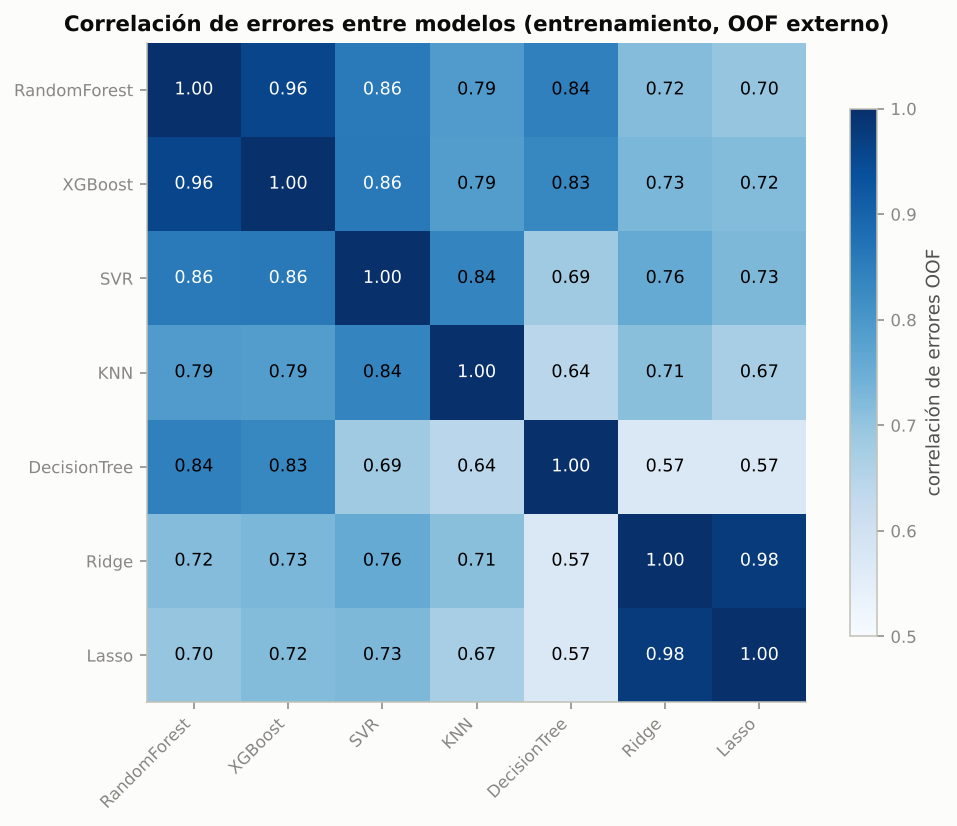

In [2]:
BEST = run_blend2.BEST
E = {}
for m, meth in BEST.items():
    parts = [pickle.load(open(C.RESULTS_DIR / "cache" / f"A_estructural__{m}__{meth}__{k}.pkl", "rb")) for k in range(10)]
    n = sum(len(p["y"]) for p in parts)
    e = np.zeros(n)
    for p in parts:
        e[p["index"]] = p["y"] - p["pred"]
    E[m] = e
E = pd.DataFrame(E)
corr = E.corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, vmin=0.5, vmax=1, cmap="Blues"); ax.grid(False)
ax.set_xticks(range(7), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(7), corr.columns)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if corr.iloc[i, j] > 0.85 else "black")
fig.colorbar(im, ax=ax, shrink=.8, label="correlación de errores OOF")
ax.set_title("Correlación de errores entre modelos (entrenamiento, OOF externo)")
fig.tight_layout(); fig.savefig(C.FIG_DIR / "hibridos_corr_errores.png", dpi=150)
plt.show()

Ningún par baja de 0.57: **todos los modelos fallan en los mismos activos**. RF y XGBoost tienen 0.96, la
pareja más redundante; SVR es el compañero fuerte más distinto (0.86).

## 3.5.2 Híbrido RF + XGBoost

In [3]:
run_blend.main()

   fold   w_RF  rho_err_inner  rmse_RF  rmse_XGB  rmse_Hibrido  rmse_Promedio50
0     0 0.7553         0.9503   1.9102    1.8298        1.8676           1.8386
1     1 0.7457         0.9310   1.5780    1.7330        1.5991           1.6319
2     2 0.8401         0.9384   1.6070    1.5145        1.5821           1.5415
3     3 0.7411         0.9268   1.5108    1.4688        1.4841           1.4690
4     4 0.6095         0.9654   3.3371    3.4514        3.3713           3.3833
5     5 0.7009         0.9370   2.0713    1.9987        2.0138           1.9919
6     6 0.6616         0.9331   1.6668    1.7479        1.6668           1.6769
7     7 0.9846         0.9327   2.2463    2.2882        2.2458           2.2491
8     8 0.5765         0.9334   1.8010    1.9097        1.8255           1.8334
9     9 0.6124         0.9405   2.3533    2.6307        2.4457           2.4762
{
 "RF": {
  "mean_diff": 0.0019896784054329155,
  "folds_better": 6,
  "wilcoxon_p": 0.384765625,
  "ttest_p": 0.555693

In [4]:
s1 = json.load(open(OUT / "summary.json", encoding="utf-8"))
th = s1["theory"]
sR, sX, sRX = th["var_eR"], th["var_eX"], th["cov_eRX"]
mse_min = (sR * sX - sRX ** 2) / (sR + sX - 2 * sRX)
print(f"ρ errores = {th['rho_err_dev']:.3f} · w* = {th['w_final']:.3f}")
print(f"MSE mínimo teórico = {mse_min:.3f} vs MSE RF = {sR:.3f} → ganancia máxima {100 * (1 - mse_min / sR):.2f} %")
print(f"w estimado en entrenamiento (train) = {th['w_final']:.2f}; w 'oráculo' en prueba (solo diagnóstico) = {s1['w_oracle_test_diagnostic']:.2f}")

ρ errores = 0.958 · w* = 0.834
MSE mínimo teórico = 4.294 vs MSE RF = 4.304 → ganancia máxima 0.23 %
w estimado en entrenamiento (train) = 0.83; w 'oráculo' en prueba (solo diagnóstico) = 0.33


Con $\rho = 0.96$ la ganancia máxima posible de la combinación es de apenas ~0.2 % del MSE. Además, el peso
es inestable: el estimado en entrenamiento (train) (0.83) y el que habría sido óptimo en prueba (0.33) son muy distintos.
Es el *forecast combination puzzle* (Smith y Wallis, 2009): cuando la ganancia potencial es pequeña, el error
de estimar $w$ se la come.

## 3.5.3 RF + SVR y Super Learner

In [5]:
run_blend2.main()

   fold  rmse_RandomForest  rmse_XGBoost  rmse_SVR  rmse_RF+SVR  rmse_SuperLearner
0     0             1.9100        1.8300    2.2310       1.9220             1.8840
1     1             1.5780        1.7330    1.6600       1.5550             1.5630
2     2             1.6070        1.5140    1.8380       1.5950             1.5710
3     3             1.5110        1.4690    1.6800       1.4670             1.4560
4     4             3.3370        3.4510    3.3980       3.3320             3.4290
5     5             2.0710        1.9990    1.7900       1.9230             1.9060
6     6             1.6670        1.7480    2.0500       1.6580             1.6680
7     7             2.2460        2.2880    2.5820       2.2530             2.2430
8     8             1.8010        1.9100    2.2120       1.8670             2.0160
9     9             2.3530        2.6310    2.4270       2.3480             2.4380
fold                4.5000
rmse_RandomForest   2.0082
rmse_XGBoost        2.0573
rmse_S

## 3.5.4 Resumen

In [6]:
f1 = pd.read_csv(OUT / "folds.csv"); f2 = pd.read_csv(OUT / "folds_mix2.csv")
t1 = pd.read_csv(OUT / "test_metrics.csv", index_col=0)
s2 = json.load(open(OUT / "summary_mix2.json", encoding="utf-8"))
t2 = pd.DataFrame(s2["test"]).T
res = pd.DataFrame({
    "RMSE CV externa": [f1.rmse_Hibrido.mean(), f2["rmse_RF+SVR"].mean(), f2.rmse_SuperLearner.mean(),
                        f1.rmse_RF.mean(), f1.rmse_XGB.mean()],
    "d.e. pliegues": [f1.rmse_Hibrido.std(), f2["rmse_RF+SVR"].std(), f2.rmse_SuperLearner.std(),
                      f1.rmse_RF.std(), f1.rmse_XGB.std()],
    "RMSE prueba": [t1.loc["Híbrido (w*)", "rmse"], t2.loc["RF+SVR", "rmse"], t2.loc["SuperLearner", "rmse"],
                    t1.loc["RandomForest", "rmse"], t1.loc["XGBoost", "rmse"]],
    "R² prueba": [t1.loc["Híbrido (w*)", "r2"], t2.loc["RF+SVR", "r2"], t2.loc["SuperLearner", "r2"],
                  t1.loc["RandomForest", "r2"], t1.loc["XGBoost", "r2"]],
}, index=["Híbrido RF+XGB", "RF+SVR", "Super Learner", "Random Forest", "XGBoost"])
res.to_csv(OUT / "resumen.csv")
res

,RMSE CV externa,d.e. pliegues,RMSE prueba,R² prueba
Híbrido RF+XGB,2.0102,0.5676,1.6782,0.9166
RF+SVR,1.9920,0.5528,1.7243,0.9119
Super Learner,2.0174,0.5862,1.7227,0.9121
Random Forest,2.0082,0.5486,1.7171,0.9127
XGBoost,2.0573,0.6004,1.6481,0.9196


In [7]:
tt = pd.concat([pd.read_csv(OUT / "tests.csv").assign(mezcla="Híbrido RF+XGB"), pd.read_csv(OUT / "tests_mix2.csv")])
tt[["mezcla", "vs", "dRMSE", "dm_hln", "dm_p", "dm_p_holm", "gw_p", "cw_p"]]

,mezcla,vs,dRMSE,dm_hln,dm_p,dm_p_holm,gw_p,cw_p
0,Híbrido RF+XGB,XGBoost,0.0301,-0.4936,0.6218,0.6218,0.1391,0.0519
1,Híbrido RF+XGB,RandomForest,-0.0388,2.6992,0.0071,0.0142,0.0154,0.0017
0,RF+SVR,XGBoost,0.0762,-0.8662,0.3867,1.0000,0.1806,0.0736
1,RF+SVR,RandomForest,0.0073,-0.2988,0.7652,1.0000,0.0919,0.1407
2,SuperLearner,XGBoost,0.0746,-0.8605,0.3898,1.0000,0.1954,0.0877
3,SuperLearner,RandomForest,0.0056,-0.2296,0.8184,1.0000,0.0596,0.0933


## Conclusión

* **Ninguna mezcla supera de forma significativa al mejor modelo individual.** En CV externa, RF + SVR logra
  el RMSE medio más bajo del proyecto (1.992), pero frente a RF la diferencia no es significativa (gana en 7
  de 10 pliegues; Wilcoxon p = 0.16; δ de Cliff despreciable). En prueba, ninguna mezcla difiere de XGBoost
  (Diebold-Mariano p ≥ 0.39) y todas entran al MCS.
* El único resultado significativo es que el híbrido RF + XGBoost mejora a RF en prueba (DM p = 0.014 con
  Holm; bootstrap por activo [−0.069, −0.013]), pero no a XGBoost.
* El Super Learner asignó 72 % a RF, 21 % a SVR y casi nada a XGBoost: para combinar importa la
  **diversidad de errores** más que el desempeño individual.
* **Explicación:** el error dominante es el efecto propio de cada activo, común a todos los modelos
  (correlaciones de error ≥ 0.57). Combinar solo reduce la parte del error que los modelos no comparten. El
  límite está en la información disponible, no en el algoritmo.